# Fashion-MNIST: dados e análise exploratória
## Detecção de anomalias com Autoencoder · Issues #2 e #3

**Responsável:** Rafael (`Rafael-Casarin`). **Etapa:** preparação e EDA, antes do treinamento.

O objetivo é preparar dados confiáveis e registrar hipóteses sobre os dois cenários do projeto:
**Bag (8)** como anomalia no cenário chamado de fácil e **Sandal (5)** no chamado de difícil.
Esses nomes expressam uma expectativa; a dificuldade real só poderá ser medida após o treino.

**Pergunta:** um Autoencoder treinado apenas com as nove classes normais terá erro de reconstrução
maior na classe que não viu?

Este notebook não treina um modelo nem apresenta métricas de detecção. Ele importa o pipeline de
`src/autoencoder/data.py`, verifica os dados reais, salva as figuras em `reports/figures/`
e registra um resumo reproduzível em `reports/eda_summary.json`.

### Protocolo e prevenção de vazamento

| Origem | Uso | Conteúdo por cenário |
|---|---|---|
| Treino oficial: 60.000 imagens | Treino do modelo | 45.900 normais (85% das 54.000 normais) |
| Treino oficial: 60.000 imagens | Validação | 8.100 normais (15% das 54.000 normais) |
| Treino oficial: 60.000 imagens | Excluídas do ajuste | 6.000 imagens da classe anômala |
| Teste oficial: 10.000 imagens | Avaliação final | 9.000 normais + 1.000 anômalas |

Os 85%/15% são aplicados **depois de excluir a classe anômala**, não sobre as 60.000 imagens.
Cada classe normal fica com 5.100 exemplos de treino e 900 de validação.

- A EDA visual usa apenas o **conjunto oficial de treino**. As imagens anômalas excluídas
  aparecem somente na descrição qualitativa do problema; nunca alimentam o ajuste do modelo ou do limiar.
- No teste, esta etapa verifica somente integridade, contagens e contrato do pipeline.
  Não inspeciona imagens de teste nem escores para orientar decisões.
- O limiar futuro deve usar apenas os erros das imagens normais de validação.
  A política de escolha do limiar deve ser definida antes da avaliação final.
- Os rótulos originais organizam os cenários e a avaliação. O alvo de reconstrução do
  Autoencoder é a própria imagem, não uma das dez classes.

### 1. Ambiente e configuração

Instale `requirements.txt` e selecione o kernel do ambiente do projeto (instruções no README).
Depois use **Restart Kernel and Run All Cells**. A primeira execução baixa aproximadamente 30 MB;
as próximas reutilizam o cache, verificando os checksums publicados pela fonte.

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib
import importlib.metadata
import json
import platform

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from autoencoder.data import (
    CLASS_NAMES, FILES, MD5, load_config, load_raw, make_splits, make_dataloaders,
)

ROOT = next(
    (p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
     if (p / "configs/default.yaml").is_file() and (p / "pyproject.toml").is_file()),
    None,
)
if ROOT is None:
    raise RuntimeError("Abra o notebook dentro do repositório do projeto.")

config = load_config(ROOT / "configs/default.yaml")
FIGURES = ROOT / "reports/figures"
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.labelcolor": "#334155",
})
NORMAL_COLOR, ANOMALY_COLOR = "#2563eb", "#db6b25"

def show_and_save(fig, filename):
    fig.savefig(FIGURES / filename, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)

versions = {name: importlib.metadata.version(name) for name in
            ("numpy", "torch", "scikit-learn", "matplotlib", "PyYAML")}
print("Python:", platform.python_version())
print("Dependências:", versions)
print(f"Seed: {config.seed} | Validação: {config.validation_fraction:.0%}")
print("A EDA verifica sempre os dois cenários: Bag (8) e Sandal (5).")

Python: 3.12.13
Dependências: {'numpy': '2.1.3', 'torch': '2.5.1+cpu', 'scikit-learn': '1.5.2', 'matplotlib': '3.9.2', 'PyYAML': '6.0.2'}
Seed: 42 | Validação: 15%
A EDA verifica sempre os dois cenários: Bag (8) e Sandal (5).


In [2]:
raw = load_raw(config.directory)
for name, array in raw.items():
    print(f"{name}: shape={array.shape}, dtype={array.dtype}")
assert raw["train_images"].shape == (60000, 28, 28)
assert raw["test_images"].shape == (10000, 28, 28)
np.testing.assert_array_equal(np.bincount(raw["train_labels"], minlength=10), [6000] * 10)
np.testing.assert_array_equal(np.bincount(raw["test_labels"], minlength=10), [1000] * 10)
print("Arquivos oficiais íntegros; dez classes balanceadas em cada partição oficial.")

source_files = {}
for filename in FILES.values():
    with (config.directory / filename).open("rb") as handle:
        digest = hashlib.file_digest(handle, "sha256").hexdigest()
    source_files[filename] = {"sha256": digest, "official_md5": MD5[filename]}

train_images: shape=(60000, 28, 28), dtype=uint8
train_labels: shape=(60000,), dtype=uint8
test_images: shape=(10000, 28, 28), dtype=uint8
test_labels: shape=(10000,), dtype=uint8
Arquivos oficiais íntegros; dez classes balanceadas em cada partição oficial.


### 2. Distribuição por classe e auditoria dos conjuntos

As barras azuis representam classes normais; a laranja identifica a classe anômala.
Uma barra de altura zero no treino e na validação é esperada para a anomalia.
As escalas verticais são próprias de cada painel, e as quantidades também são apresentadas na tabela.

A auditoria verifica: ausência de anomalias no ajuste, cobertura exata dos exemplos normais,
índices disjuntos, repetibilidade da seed, alinhamento imagem/rótulo e normalização.

Auditoria aprovada nos dois cenários.


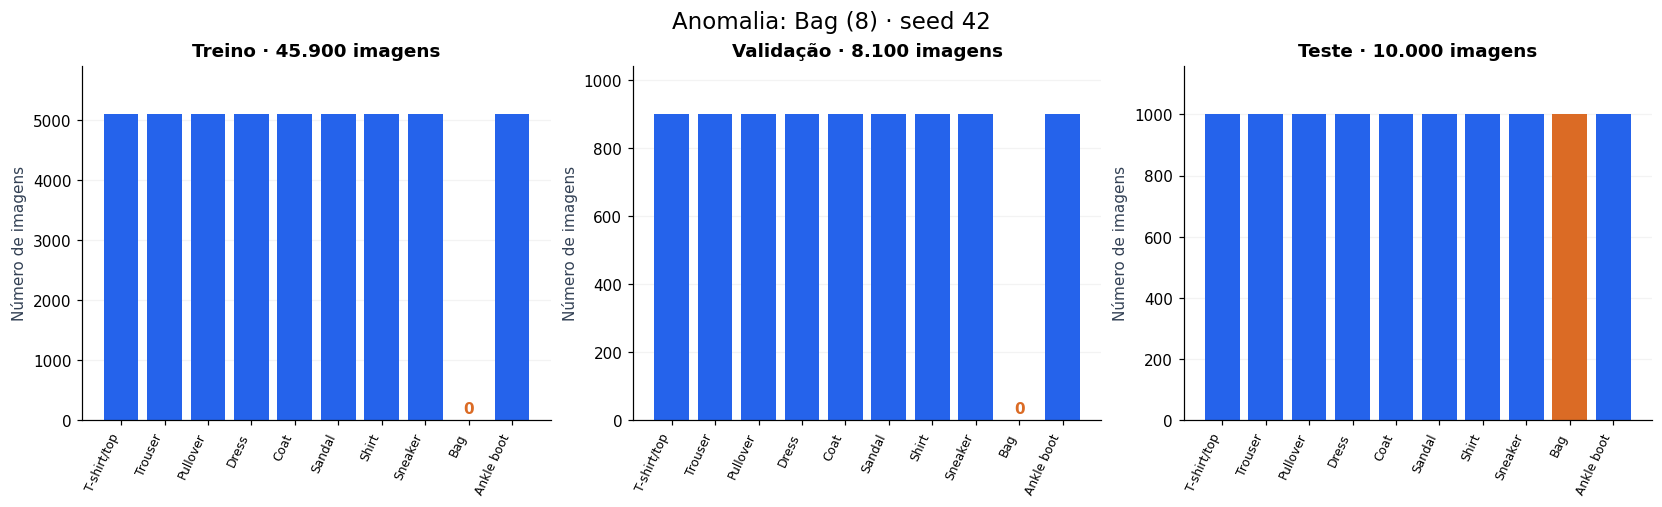

**Cenário Bag**

| Classe | Treino | Validação | Teste |
|---|---:|---:|---:|
| 0 · T-shirt/top | 5100 | 900 | 1000 |
| 1 · Trouser | 5100 | 900 | 1000 |
| 2 · Pullover | 5100 | 900 | 1000 |
| 3 · Dress | 5100 | 900 | 1000 |
| 4 · Coat | 5100 | 900 | 1000 |
| 5 · Sandal | 5100 | 900 | 1000 |
| 6 · Shirt | 5100 | 900 | 1000 |
| 7 · Sneaker | 5100 | 900 | 1000 |
| 8 · Bag | 0 | 0 | 1000 |
| 9 · Ankle boot | 5100 | 900 | 1000 |

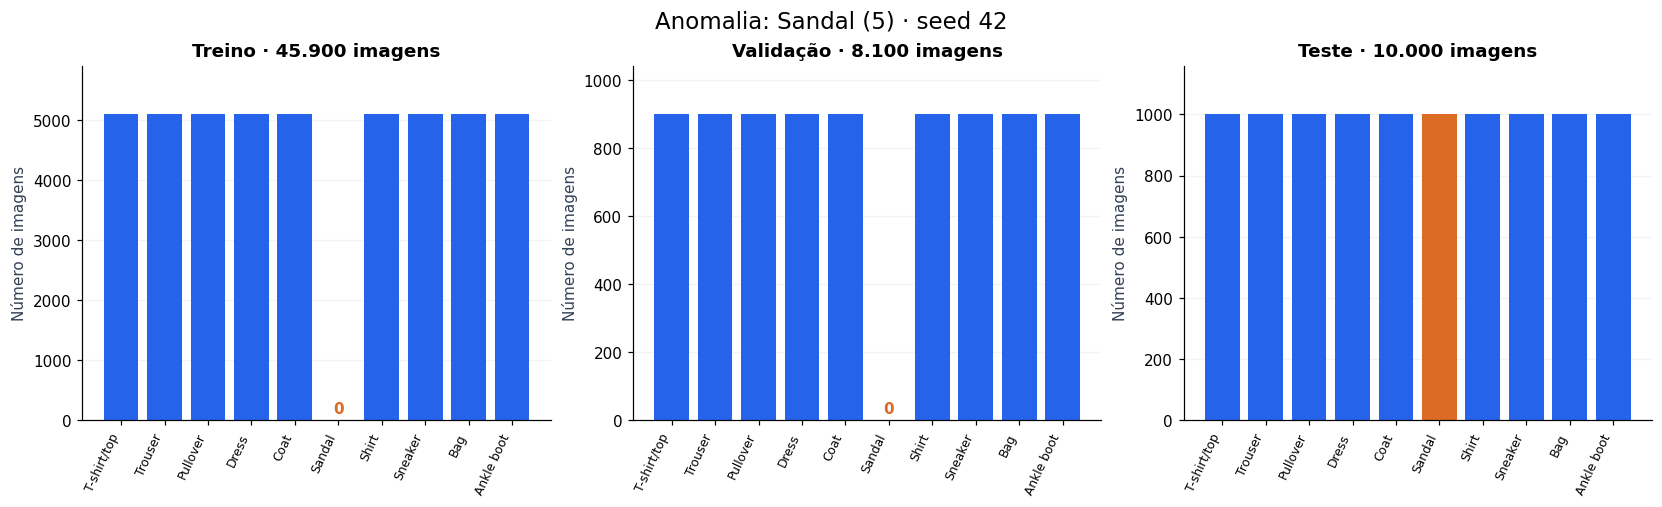

**Cenário Sandal**

| Classe | Treino | Validação | Teste |
|---|---:|---:|---:|
| 0 · T-shirt/top | 5100 | 900 | 1000 |
| 1 · Trouser | 5100 | 900 | 1000 |
| 2 · Pullover | 5100 | 900 | 1000 |
| 3 · Dress | 5100 | 900 | 1000 |
| 4 · Coat | 5100 | 900 | 1000 |
| 5 · Sandal | 0 | 0 | 1000 |
| 6 · Shirt | 5100 | 900 | 1000 |
| 7 · Sneaker | 5100 | 900 | 1000 |
| 8 · Bag | 5100 | 900 | 1000 |
| 9 · Ankle boot | 5100 | 900 | 1000 |

In [3]:
scenario_summaries = {}
for anomaly in (8, 5):
    splits = make_splits(raw, anomaly, config.validation_fraction, config.seed)
    repeated = make_splits(raw, anomaly, config.validation_fraction, config.seed)
    overlap = np.intersect1d(splits.train.indices, splits.val.indices).size
    assert overlap == 0
    normal_indices = np.flatnonzero(raw["train_labels"] != anomaly)
    used_indices = np.r_[splits.train.indices, splits.val.indices]
    np.testing.assert_array_equal(np.sort(used_indices), normal_indices)
    assert np.unique(used_indices).size == used_indices.size
    assert anomaly not in splits.train.labels and anomaly not in splits.val.labels
    np.testing.assert_array_equal(splits.test.labels, raw["test_labels"])

    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), layout="constrained")
    rows = ["| Classe | Treino | Validação | Teste |", "|---|---:|---:|---:|"]
    counts_by_split = {}
    details = {}
    for ax, name, title in zip(axes, ("train", "val", "test"), ("Treino", "Validação", "Teste")):
        split = getattr(splits, name)
        assert split.images.dtype == np.float32 and np.isfinite(split.images).all()
        assert 0 <= split.images.min() <= split.images.max() <= 1
        np.testing.assert_array_equal(split.indices, getattr(repeated, name).indices)
        np.testing.assert_array_equal(split.images, getattr(repeated, name).images)
        counts = np.bincount(split.labels, minlength=10)
        counts_by_split[name] = counts
        ax.bar(range(10), counts, color=[ANOMALY_COLOR if c == anomaly else NORMAL_COLOR for c in range(10)])
        ax.set_xticks(range(10), CLASS_NAMES, rotation=65, ha="right", fontsize=8)
        ax.set_title(f"{title} · {len(split.labels):,} imagens".replace(",", "."))
        ax.set_ylabel("Número de imagens")
        ax.set_ylim(0, max(counts) * 1.16)
        ax.grid(axis="y", alpha=.15)
        ax.set_axisbelow(True)
        if name != "test":
            ax.annotate("0", (anomaly, 0), xytext=(0, 5), textcoords="offset points",
                        ha="center", color=ANOMALY_COLOR, weight="bold")
        details[name] = {
            "n": len(split.labels), "counts": counts.tolist(), "source": split.source,
            "anomalies": int((split.labels == anomaly).sum()),
            "pixel_min": float(split.images.min()), "pixel_max": float(split.images.max()),
            "indices_sha256": hashlib.sha256(split.indices.astype("<i8").tobytes()).hexdigest(),
        }
    fig.suptitle(f"Anomalia: {CLASS_NAMES[anomaly]} ({anomaly}) · seed {config.seed}", fontsize=15)
    show_and_save(fig, f"class_distribution_{anomaly}.png")
    for cls, label in enumerate(CLASS_NAMES):
        rows.append(f"| {cls} · {label} | " + " | ".join(str(counts_by_split[n][cls]) for n in ("train", "val", "test")) + " |")
    display(Markdown(f"**Cenário {CLASS_NAMES[anomaly]}**\n\n" + "\n".join(rows)))
    scenario_summaries[str(anomaly)] = {
        "anomaly_class": anomaly, "anomaly_name": CLASS_NAMES[anomaly],
        "excluded_official_train_anomalies": int((raw["train_labels"] == anomaly).sum()),
        "train_val_overlap": int(overlap), "same_seed_identical": True, "splits": details,
    }
    del repeated, splits

print("Auditoria aprovada nos dois cenários.")

**Interpretação:** o conjunto original é balanceado por classe, mas o problema binário de detecção
tem **10% de anomalias no teste**. Um detector que sempre responde “normal” teria 90% de acurácia
e recall zero para anomalias. Portanto, acurácia isolada não é uma boa medida do objetivo.
Na avaliação futura, será necessário analisar recall, precisão, curvas e erros individuais.

Os índices de treino/validação identificam registros no arquivo oficial de treino. Os índices de
teste pertencem a outro arquivo; comparar apenas seus números entre origens não mede vazamento.
Esta auditoria garante separação por registro de origem, não prova ausência de imagens visualmente duplicadas na fonte.

### 3. Exemplos visuais por classe

Selecionamos seis imagens de cada classe do **treino oficial**, com uma seed fixa.
Cada linha mostra variações internas da classe. Bag e Sandal aparecem para caracterizar
os cenários, embora sejam removidas dos conjuntos de ajuste quando escolhidas como anomalia.

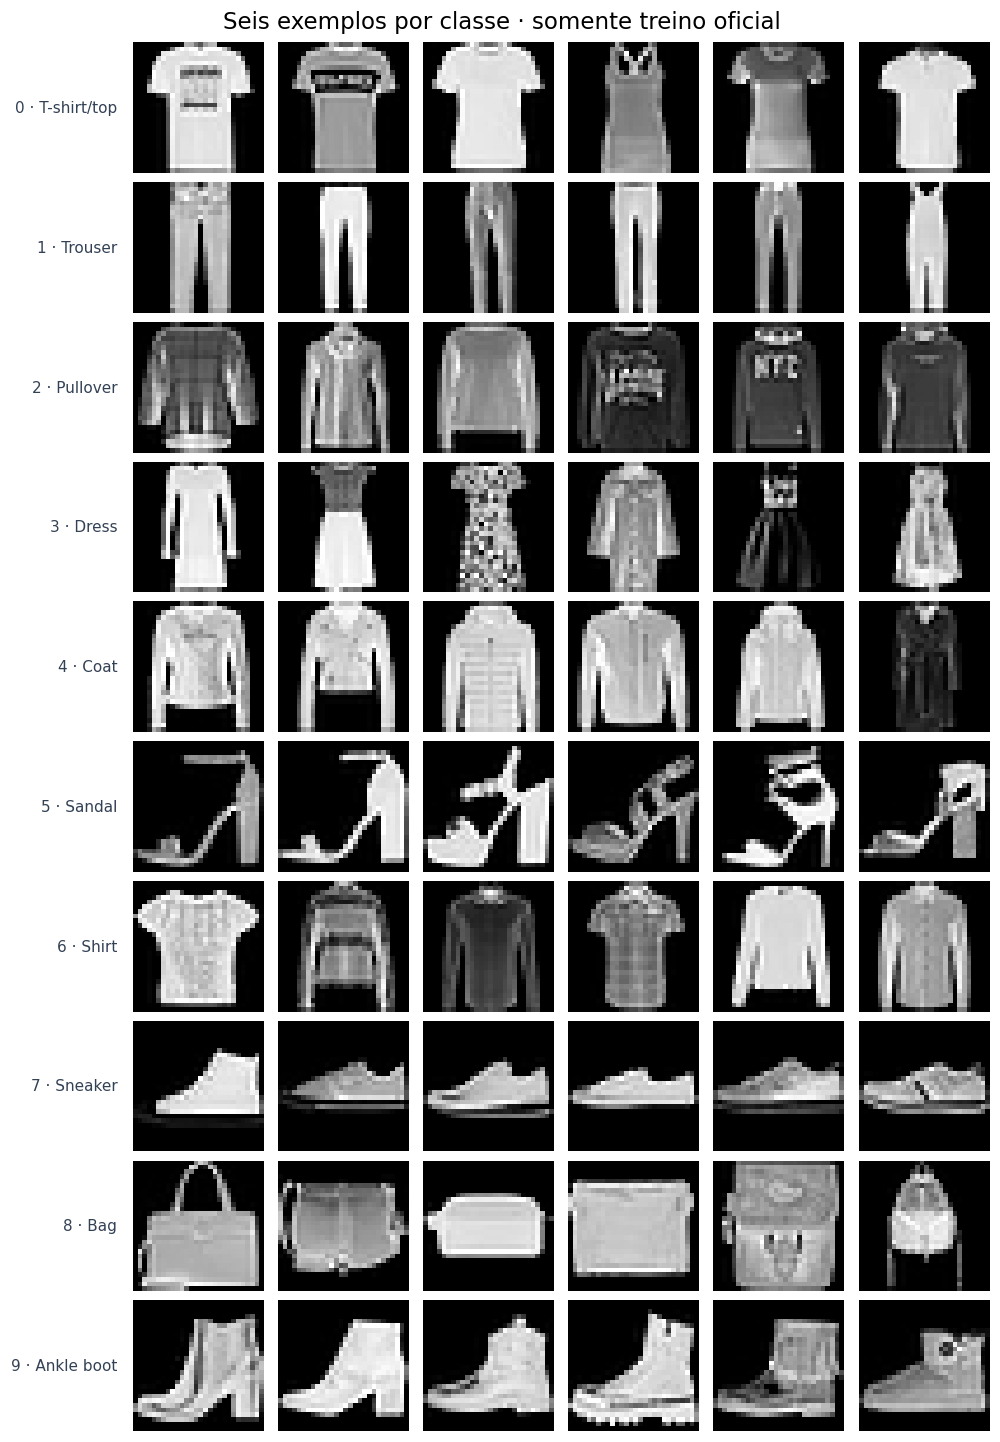

In [4]:
eda_images, eda_labels = raw["train_images"], raw["train_labels"]
rng = np.random.default_rng(config.seed)
fig, axes = plt.subplots(10, 6, figsize=(9, 13), layout="constrained")
example_indices = {}
for cls in range(10):
    indices = rng.choice(np.flatnonzero(eda_labels == cls), size=6, replace=False)
    example_indices[str(cls)] = indices.tolist()
    for col, index in enumerate(indices):
        ax = axes[cls, col]
        ax.imshow(eda_images[index], cmap="gray", vmin=0, vmax=255, interpolation="nearest")
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
        if col == 0:
            ax.set_ylabel(f"{cls} · {CLASS_NAMES[cls]}", rotation=0, ha="right", va="center", labelpad=10)
fig.suptitle("Seis exemplos por classe · somente treino oficial", fontsize=15)
show_and_save(fig, "examples_by_class.png")

**O que observar:** T-shirt/top, Shirt, Pullover e Coat compartilham a organização de tronco e mangas.
Sandal, Sneaker e Ankle boot compartilham elementos da silhueta de calçados, mas diferem em altura
e preenchimento. Bolsas têm grande variação de formato e alças; uma única imagem não representa a classe inteira.
Essas semelhanças sugerem perguntas para o modelo, não demonstram como ele irá se comportar.

### 4. Imagem média de cada classe

A média utiliza as 6.000 imagens de cada classe do treino oficial, normalizadas para [0, 1].
Mantemos a mesma escala de cor em todos os painéis. A média destaca o contorno predominante,
mas suaviza detalhes e pode esconder subgrupos.

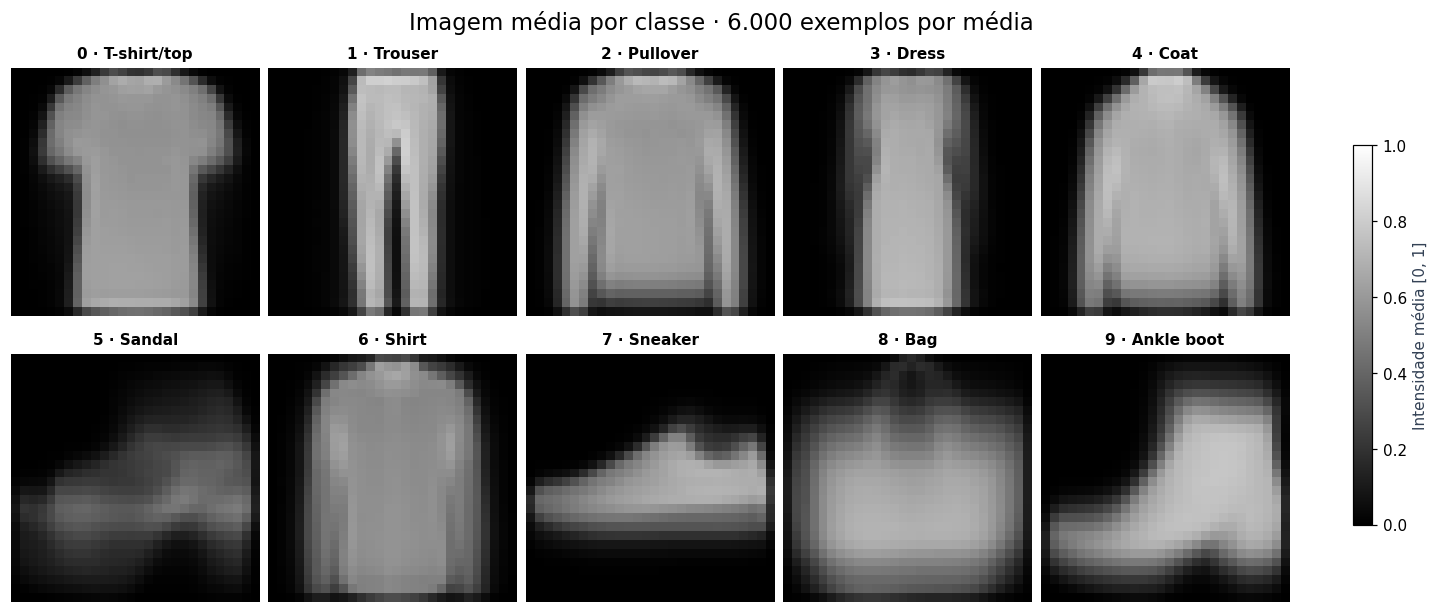

In [5]:
mean_images = np.stack([
    eda_images[eda_labels == cls].mean(axis=0) / 255.0 for cls in range(10)
])
fig, axes = plt.subplots(2, 5, figsize=(13, 5.5), layout="constrained")
for cls, ax in enumerate(axes.flat):
    im = ax.imshow(mean_images[cls], cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    ax.set_title(f"{cls} · {CLASS_NAMES[cls]}", fontsize=10)
    ax.axis("off")
fig.colorbar(im, ax=list(axes.flat), shrink=.7, label="Intensidade média [0, 1]")
fig.suptitle("Imagem média por classe · 6.000 exemplos por média", fontsize=15)
show_and_save(fig, "mean_image_by_class.png")

### 5. Intensidade dos pixels e quantidade de fundo

Um pixel preto vale zero; um branco, um. A distribuição é calculada sobre **todos os pixels**
das imagens de cada classe do treino oficial, usando as mesmas 32 faixas. O eixo vertical
logarítmico permite enxergar tanto a concentração de fundo quanto intensidades menos frequentes.
O fundo entra no histograma e no erro de reconstrução; ele não deve ser interpretado como ruído a remover automaticamente.

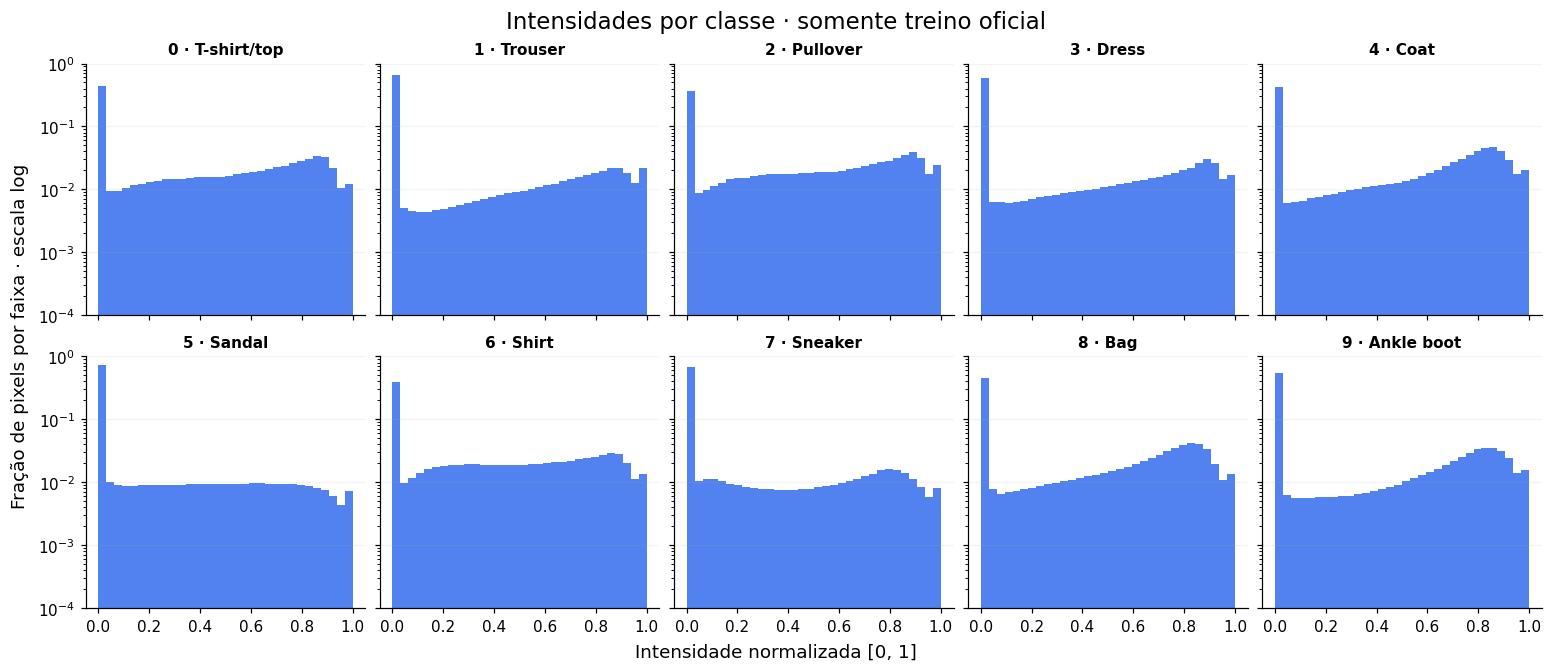

| Classe | Média | Desvio padrão | Pixels iguais a zero |
|---|---:|---:|---:|
| T-shirt/top | 0.3256 | 0.3507 | 40.6% |
| Trouser | 0.2229 | 0.3435 | 65.1% |
| Pullover | 0.3767 | 0.3587 | 35.1% |
| Dress | 0.2589 | 0.3542 | 57.2% |
| Coat | 0.3853 | 0.3763 | 39.8% |
| Sandal | 0.1367 | 0.2631 | 67.9% |
| Shirt | 0.3318 | 0.3393 | 37.1% |
| Sneaker | 0.1677 | 0.2948 | 66.2% |
| Bag | 0.3536 | 0.3653 | 41.4% |
| Ankle boot | 0.3012 | 0.3705 | 51.5% |

In [6]:
class_statistics = []
fig, axes = plt.subplots(2, 5, figsize=(14, 6), sharex=True, sharey=True, layout="constrained")
edges = np.linspace(0, 1, 33)
for cls, ax in enumerate(axes.flat):
    images = eda_images[eda_labels == cls]
    counts, _ = np.histogram(images.astype(np.float32) / np.float32(255), bins=edges)
    probability = counts / counts.sum()
    ax.stairs(probability, edges, fill=True, color=NORMAL_COLOR, alpha=.8)
    ax.set_yscale("log")
    ax.set_ylim(1e-4, 1)
    ax.set_title(f"{cls} · {CLASS_NAMES[cls]}", fontsize=10)
    ax.grid(axis="y", alpha=.15)
    class_statistics.append({
        "class": cls, "name": CLASS_NAMES[cls], "n": len(images),
        "mean_intensity": float(images.mean() / 255),
        "std_intensity": float(images.std() / 255),
        "zero_pixel_fraction": float((images == 0).mean()),
    })
fig.supxlabel("Intensidade normalizada [0, 1]")
fig.supylabel("Fração de pixels por faixa · escala log")
fig.suptitle("Intensidades por classe · somente treino oficial", fontsize=15)
show_and_save(fig, "pixel_intensity_by_class.png")

rows = ["| Classe | Média | Desvio padrão | Pixels iguais a zero |", "|---|---:|---:|---:|"]
for item in class_statistics:
    rows.append(f"| {item['name']} | {item['mean_intensity']:.4f} | {item['std_intensity']:.4f} | {item['zero_pixel_fraction']:.1%} |")
display(Markdown("\n".join(rows)))

**Leitura dos valores observados:** Sandal tem intensidade média de **0,1367** e **67,9%** de pixels iguais a zero; Sneaker tem média **0,1677** e **66,2%** de zeros. Bag tem média **0,3536** e **41,4%** de zeros. Isso reforça investigar o efeito do fundo no erro de reconstrução. A intensidade de Bag se sobrepõe à de roupas; brilho médio sozinho não prova separação entre normal e anômalo.

### 6. Variação de intensidade entre imagens

Cada observação do boxplot abaixo é a intensidade média de uma imagem inteira.
Ele complementa o histograma: duas classes podem ter médias parecidas e silhuetas diferentes.
Os pontos além dos bigodes são observações extremas nessa estatística; **não** são automaticamente anomalias do projeto.

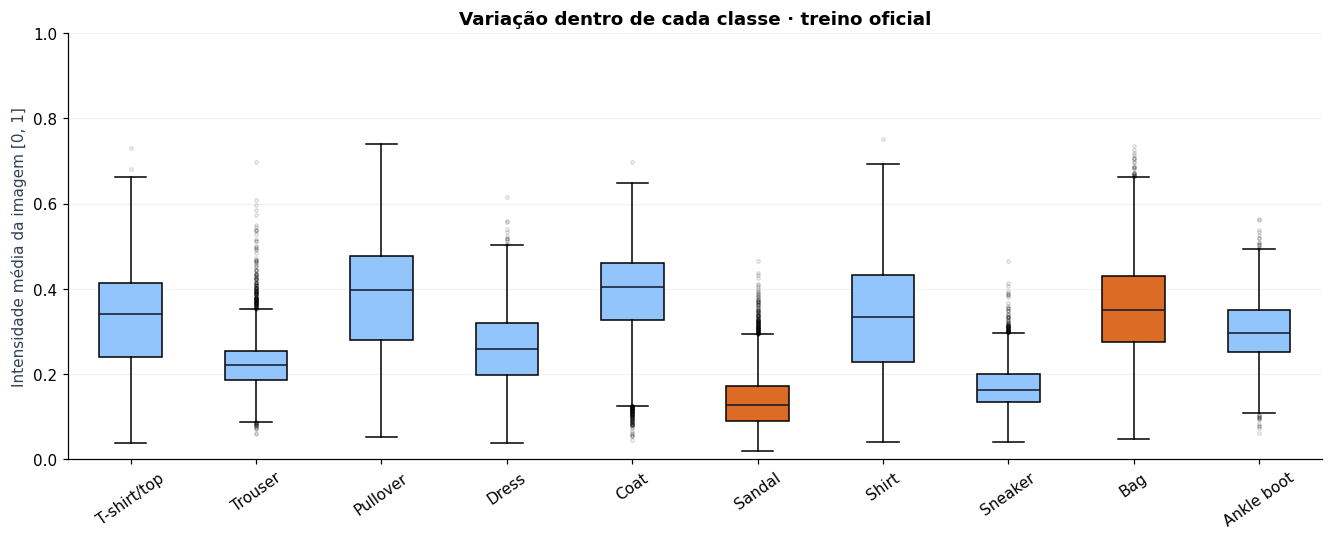

In [7]:
per_image_intensity = [eda_images[eda_labels == cls].mean(axis=(1, 2)) / 255 for cls in range(10)]
fig, ax = plt.subplots(figsize=(12, 4.8), layout="constrained")
boxes = ax.boxplot(per_image_intensity, tick_labels=CLASS_NAMES, patch_artist=True,
                   flierprops={"markersize": 2, "alpha": .15}, medianprops={"color": "#0f172a"})
for cls, box in enumerate(boxes["boxes"]):
    box.set_facecolor(ANOMALY_COLOR if cls in (5, 8) else "#93c5fd")
ax.tick_params(axis="x", rotation=35)
ax.set_ylim(0, 1)
ax.set_ylabel("Intensidade média da imagem [0, 1]")
ax.set_title("Variação dentro de cada classe · treino oficial")
ax.grid(axis="y", alpha=.15)
show_and_save(fig, "mean_intensity_per_image.png")

### 7. Hipóteses registradas antes do treino

| Hipótese | Justificativa a partir da EDA | Como verificar depois |
|---|---|---|
| H1 — Bag terá erros maiores que a maioria dos normais | Formas e alças diferem de vários padrões de roupa e calçado presentes no treino | Comparar as distribuições dos erros e a separação nos dois cenários após congelar o protocolo |
| H2 — Sandal pode gerar mais falsos negativos | Compartilha partes da silhueta com outros calçados; regiões vazias podem reduzir o erro médio | Inspecionar reconstruções e os erros das sandálias que ficarem abaixo do limiar |
| H3 — Normais incomuns podem gerar falsos positivos | Há variação dentro das classes; a imagem média não representa todos os exemplos | Agrupar falsos positivos por classe normal e examinar exemplos individuais |

**Cenário Bag:** esperamos maior separação entre erros de normais e anômalos, mas um
Autoencoder flexível pode reconstruir bolsas usando padrões gerais aprendidos.
Maior semelhança de forma também não implica necessariamente menor erro.

**Cenário Sandal:** a semelhança com Sneaker e Ankle boot pode facilitar reconstruções parciais.
Além disso, imagens com muito fundo preto podem alcançar erro médio baixo mesmo sem reconstruir bem
a região do objeto. O resultado pode contrariar o rótulo “difícil”; isto deverá ser registrado, não escondido.

**Classes parecidas:** a EDA sugere atenção a T-shirt/top–Shirt e Pullover–Coat–Shirt,
além do grupo de calçados. Não estamos treinando um classificador de dez classes:
essa observação ajuda a discutir quais padrões o Autoencoder pode reutilizar.

**Regra para a próxima etapa:** manter arquitetura, seed, divisão e política de limiar comparáveis
entre cenários. Estimar o limiar somente com erros de validação normal. Congelar o procedimento antes
de calcular métricas no teste. Para precisão–recall, registrar explicitamente se será usada Average
Precision ou área trapezoidal; são resumos diferentes. Não escolher hiperparâmetros pela métrica final de teste.

### 8. Contrato dos DataLoaders e resumo da execução

O lote contém imagens `float32` com formato `(N, 1, 28, 28)` e classes originais `int64`.
Somente o loader de treino embaralha; nenhum conjunto descarta o último lote.
Para uma rede totalmente conectada, a próxima etapa pode usar `images.flatten(1)` para obter 784 entradas.
Para o alvo binário de avaliação, use `labels == anomaly_class`.

In [8]:
selected = make_splits(raw, config.anomaly_class, config.validation_fraction, config.seed)
loaders = make_dataloaders(selected, config.batch_size, config.num_workers)
for name, loader in loaders.items():
    images, labels = next(iter(loader))
    print(f"{name}: imagens {tuple(images.shape)} {images.dtype}; rótulos {tuple(labels.shape)} {labels.dtype}")
print("Alvo da função de perda de reconstrução: a própria imagem de entrada.")

summary = {
    "scope": "Issues #2 e #3: dados e EDA; nenhum modelo treinado",
    "eda_source": "official_train_only",
    "seed": config.seed, "validation_fraction": config.validation_fraction,
    "python": platform.python_version(), "versions": versions,
    "source_files": source_files, "scenarios": scenario_summaries,
    "class_statistics_official_train": class_statistics,
    "example_indices_official_train": example_indices,
    "hypotheses_before_training": [
        "H1: Bag tende a maior erro/separação, sem garantia de ser o cenário mais fácil.",
        "H2: Sandal pode ter falsos negativos por semelhança com calçados e grande área de fundo.",
        "H3: Exemplos incomuns de classes normais podem produzir falsos positivos.",
    ],
    "figures": [f"class_distribution_{c}.png" for c in (8, 5)] + [
        "examples_by_class.png", "mean_image_by_class.png",
        "pixel_intensity_by_class.png", "mean_intensity_per_image.png",
    ],
}
assert all((FIGURES / name).is_file() for name in summary["figures"])
summary_path = ROOT / "reports/eda_summary.json"
summary_path.write_text(json.dumps(summary, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
print("Salvos: reports/eda_summary.json e", len(summary["figures"]), "figuras em reports/figures/.")

train: imagens (128, 1, 28, 28) torch.float32; rótulos (128,) torch.int64
val: imagens (128, 1, 28, 28) torch.float32; rótulos (128,) torch.int64
test: imagens (128, 1, 28, 28) torch.float32; rótulos (128,) torch.int64
Alvo da função de perda de reconstrução: a própria imagem de entrada.
Salvos: reports/eda_summary.json e 6 figuras em reports/figures/.


### Conclusão desta etapa

O pipeline preserva o teste oficial e permite alternar a classe anômala sem alterar o método de preparação.
Nos dois cenários padrão, os conjuntos têm 45.900 imagens normais de treino, 8.100 de validação e
10.000 de teste, com 1.000 anômalas. As verificações acima documentam o que foi medido nesta execução.

A EDA mostra quais comparações o grupo deve investigar na reconstrução. **Ainda não é possível
afirmar qual cenário será mais fácil nem qual será o desempenho do detector.** Essas respostas dependem
das etapas de modelagem, treinamento, definição do limiar e avaliação.

### Fontes

- [Zalando Research — Fashion-MNIST: arquivos, classes e checksums](https://github.com/zalandoresearch/fashion-mnist)
- [Xiao, Rasul e Vollgraf (2017) — Fashion-MNIST](https://arxiv.org/abs/1708.07747)
- [scikit-learn 1.5 — train_test_split](https://scikit-learn.org/1.5/modules/generated/sklearn.model_selection.train_test_split.html)
- [PyTorch — dados e DataLoaders](https://pytorch.org/docs/stable/data.html)
- [Issue #2 — pipeline de dados](https://github.com/4SemestreDonaduzzi/aprendizado-nao-supervisionado/issues/2)
- [Issue #3 — análise exploratória](https://github.com/4SemestreDonaduzzi/aprendizado-nao-supervisionado/issues/3)